In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None, weights=None, bary_lifted_pca=None):

    if weights is None:
        weights = np.ones(len(eig_lifted))

    min_weights = weights.min()
    max_weights = weights.max()
    diff = max_weights - min_weights
    
    if diff == 0:
        alpha = weights
    else:
        alpha = 0.05 + 0.95 * (weights - min_weights) / diff

    index_max_alpha = np.argmax(alpha)

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    if bary_lifted_pca is not None:
        pc = ts[:,None] * bary_lifted_pca[0][None]
        plt.plot(pc[:,0], pc[:,1], c="orange", lw=3, label="Barycenter Lifted PCA")

    pc = ts[:,None] * eig_distr_pca[0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="Distributional PCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]

        if k == index_max_alpha:
            plt.plot(pc[:,0], pc[:,1], c="orange", label="Lifted PCA", alpha=alpha[k])
        else:
            plt.plot(pc[:,0], pc[:,1], c="orange", alpha=alpha[k])

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

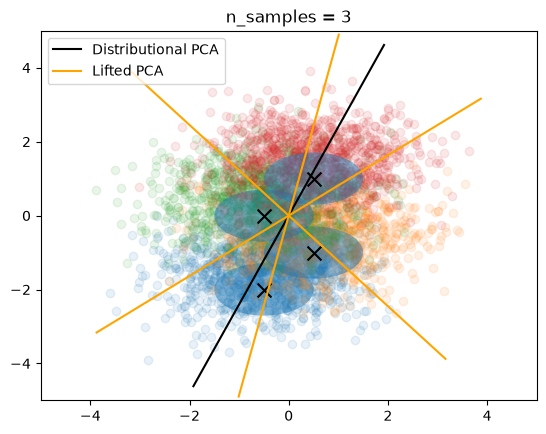

n=3 Lifted 0.3287441027738317 Distributional 1.2155725224331426


In [5]:
# Vary number of Dirac
for n_samples in [3]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, lifted_pca.center_data(samples), means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

In [6]:
n_samples = 100
d = 2

k = 10

for j in range(1, 11):
    Z = torch.randn(k, d, 1, dtype=samples.dtype).to(samples.device)
    support_bary, _ = torch.linalg.qr(Z)

    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.components_ = support_bary
    lifted_pca.weights_ = None
    lifted_pca.center_data(samples)
    print(lifted_pca.cost_barycenter(samples))

tensor(0.1839)
tensor(0.2141)
tensor(0.2804)
tensor(0.2016)
tensor(0.1600)
tensor(0.5444)
tensor(0.3844)
tensor(0.2358)
tensor(0.2313)
tensor(0.4875)


In [7]:
samples.shape

torch.Size([4, 1000, 2])

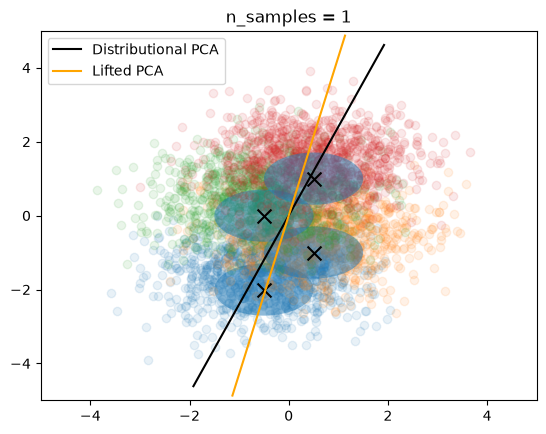

n=1 Lifted 1.2342750193343694 Distributional 1.2155725224331426


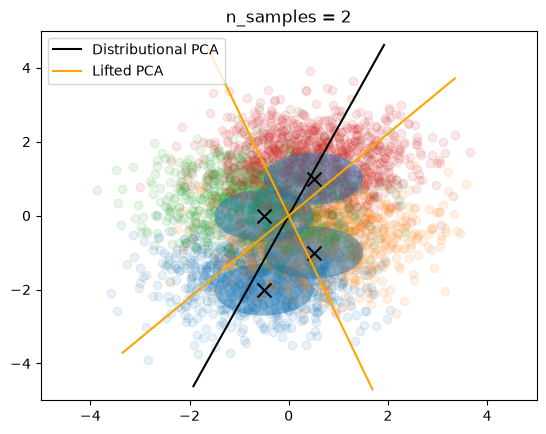

n=2 Lifted 0.5492727275307202 Distributional 1.2155725224331426


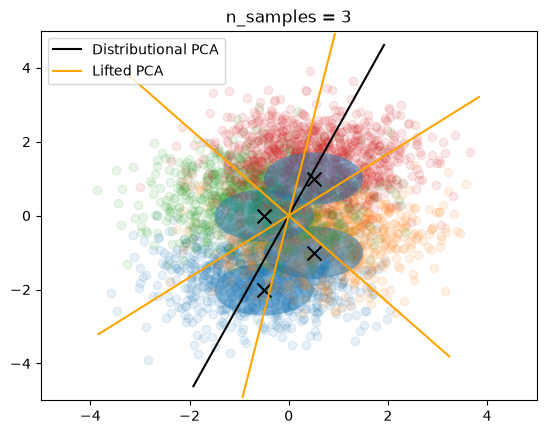

n=3 Lifted 0.329381692243761 Distributional 1.2155725224331426


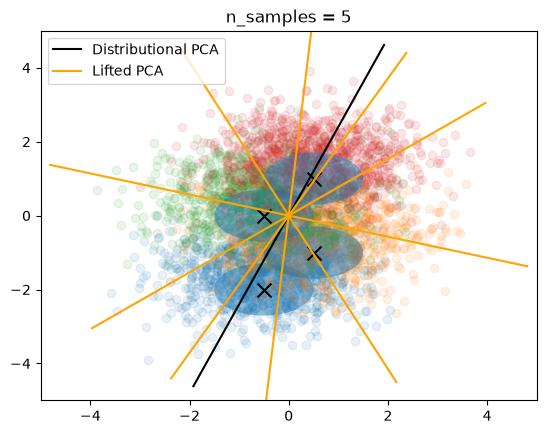

n=5 Lifted 0.17467386808954674 Distributional 1.2155725224331426


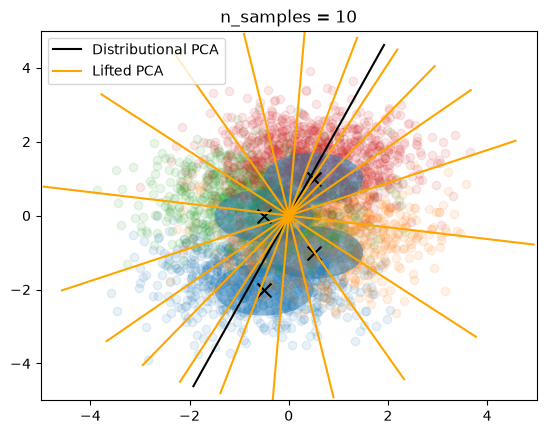

n=10 Lifted 0.09486111044031992 Distributional 1.2155725224331426


In [8]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples).item(),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

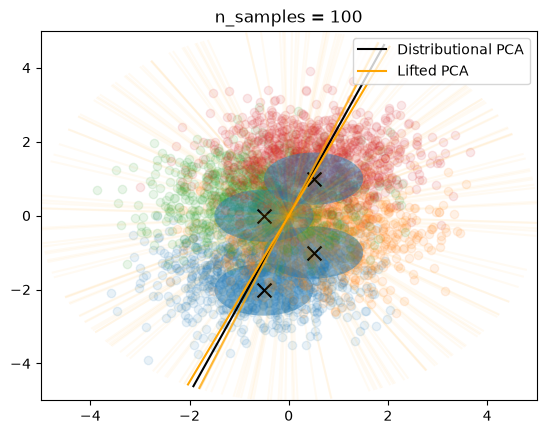

Barycenter cost: tensor(1.1564)


In [9]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

In [10]:
lifted_pca.weights_

tensor([3.8463e-06, 1.8403e-07, 2.1934e-05, 8.5875e-06, 1.4951e-04, 1.1660e-06,
        3.8600e-06, 1.9086e-07, 3.5787e-04, 9.3156e-07, 5.7782e-06, 3.3357e-06,
        9.4063e-05, 3.6870e-07, 5.0882e-03, 9.1033e-06, 7.8934e-06, 4.0254e-07,
        2.3965e-07, 3.1340e-07, 6.1028e-07, 2.2285e-02, 7.0179e-06, 1.4858e-05,
        2.2757e-06, 3.0623e-07, 1.4734e-07, 8.6447e-06, 1.8271e-06, 2.1971e-07,
        6.3981e-06, 6.6444e-07, 9.8036e-07, 7.8993e-07, 3.8923e-07, 2.1631e-07,
        9.5457e-07, 1.7651e-07, 3.1796e-06, 3.6824e-01, 2.3077e-06, 1.8039e-07,
        3.7034e-07, 1.5667e-07, 3.7207e-05, 6.5086e-06, 2.3475e-07, 2.2908e-06,
        1.5330e-03, 6.7510e-05, 1.7901e-06, 1.4305e-07, 5.5712e-07, 1.1087e-05,
        4.6954e-04, 2.7294e-05, 1.5703e-07, 1.4930e-05, 1.6988e-07, 1.4455e-07,
        3.6642e-07, 2.0912e-04, 3.4562e-07, 1.4745e-07, 1.8899e-07, 2.5417e-07,
        1.5909e-07, 8.5335e-07, 4.8845e-07, 2.2679e-07, 3.2385e-07, 3.2828e-05,
        1.0083e-05, 3.3457e-07, 1.4288e-

In [11]:
lifted_pca.weights_.max()

tensor(0.4995)

In [12]:
lifted_pca_support = LiftedPCA(n_components=1, n_samples=100)
lifted_pca_support.fit(samples)
eigenvectors_lifted = lifted_pca_support.components_

print(
    "n="+str(n_samples), "Lifted", lifted_pca_support.cost_barycenter(samples).item()
)

n=10 Lifted 0.06661132473324721


In [14]:
# Fix the support and optim over weights only
lifted_pca_weights = LiftedPCA(n_components=1, n_samples=100)
lifted_pca_weights.fit(samples, lifted_pca_support.components_, solver="fixed_support", mode="proximal", 
                       seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca_weights.components_

print("Barycenter cost:", lifted_pca_weights.cost_barycenter(samples))

Barycenter cost: tensor(1.1829)


In [16]:
import ot
from lib_pca.utils_barycenters import cost_pca

support = lifted_pca_support.components_
uniform_weights = torch.ones(100) / 100

C_list = [
    cost_pca(support, lifted_pca_support.center_data(samples)[k])
    for k in range(len(samples))
]

uniform_cost = torch.mean(torch.stack([
    ot.emd2(uniform_weights, torch.ones(len(samples[k])) / len(samples[k]), C_list[k])
    for k in range(len(samples))
]))

optimized_cost = lifted_pca_weights.cost_barycenter(samples)

print("uniform cost:", uniform_cost)
print("optimized cost:", optimized_cost)
print("weight sum:", lifted_pca_weights.weights_.sum())

uniform cost: tensor(0.0666)
optimized cost: tensor(1.1829)
weight sum: tensor(1.)


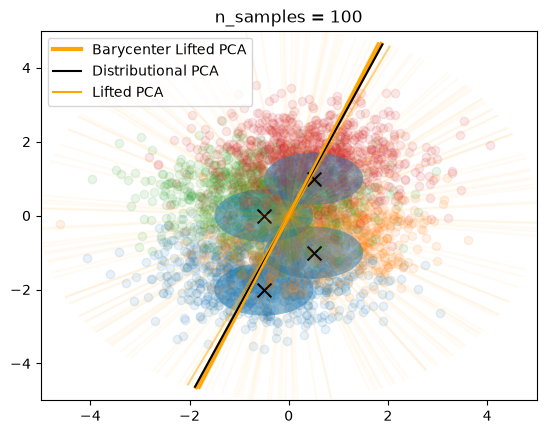

Barycenter cost: 1.1079092519694995


In [ ]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

bary_lifted_pca = lifted_pca.get_barycenter_components().T

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy(), bary_lifted_pca=bary_lifted_pca)

print("Barycenter cost:", lifted_pca.cost_barycenter(samples))

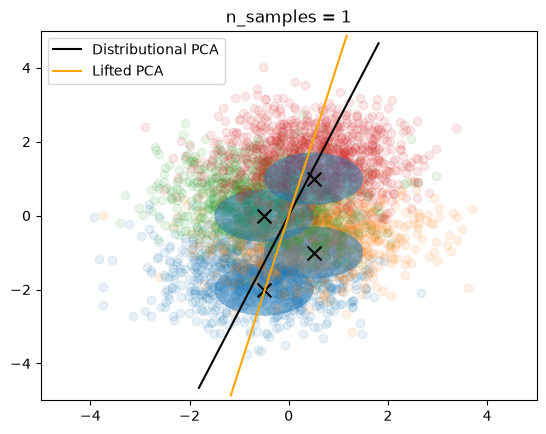

n=1 Lifted 1.1402888596057892 Distributional 1.126773715019226
[1.]


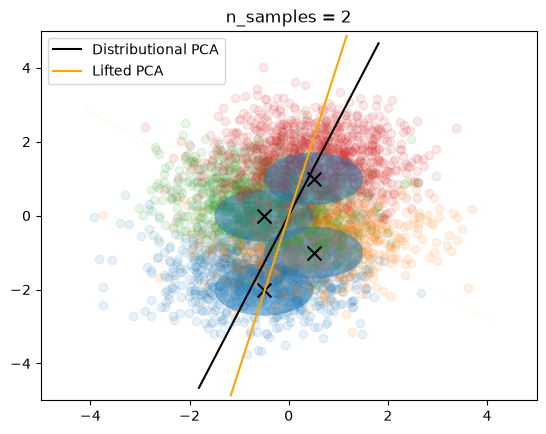

n=2 Lifted 1.1402887552976608 Distributional 1.126773715019226
[8.023855e-09 1.000000e+00]


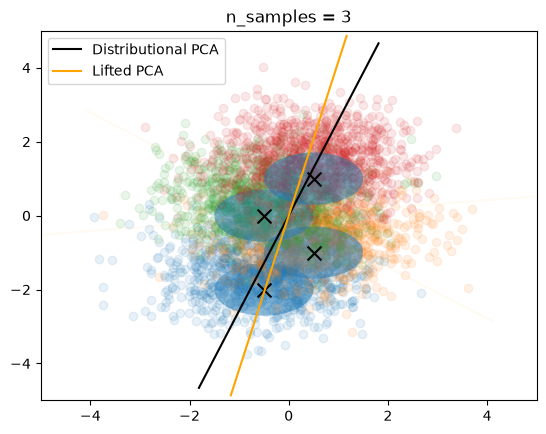

n=3 Lifted 1.140288308262825 Distributional 1.126773715019226
[1.00000000e+00 1.03082515e-10 1.80472064e-08]


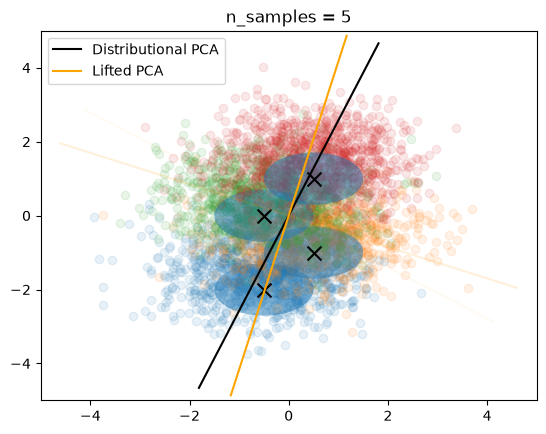

n=5 Lifted 1.1402882039546967 Distributional 1.126773715019226
[6.41374279e-15 1.38759635e-08 8.59172994e-16 6.69900613e-15
 1.00000000e+00]


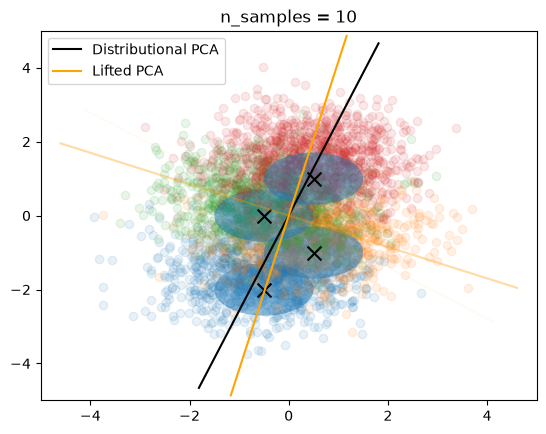

n=10 Lifted 1.140288233757019 Distributional 1.126773715019226
[1.2191488e-13 7.7250151e-12 3.0854312e-13 6.3434544e-13 2.1133881e-11
 1.2188011e-12 1.2283596e-13 1.0000000e+00 3.4289537e-12 1.2539900e-08]


In [ ]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 1 Clear PC

In [9]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

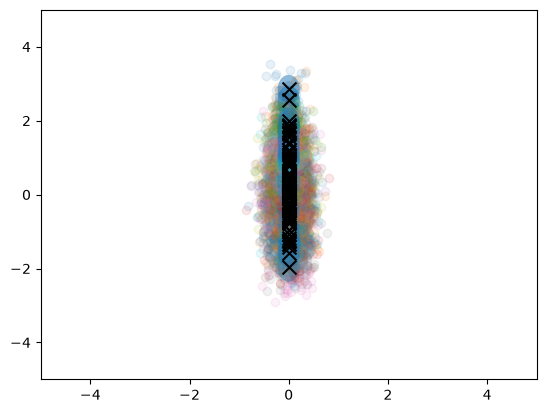

In [10]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

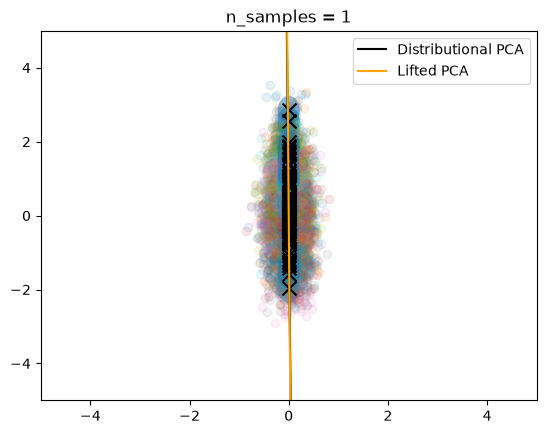

n=1 Lifted 0.05051559628918767 Distributional 0.05051364794373512


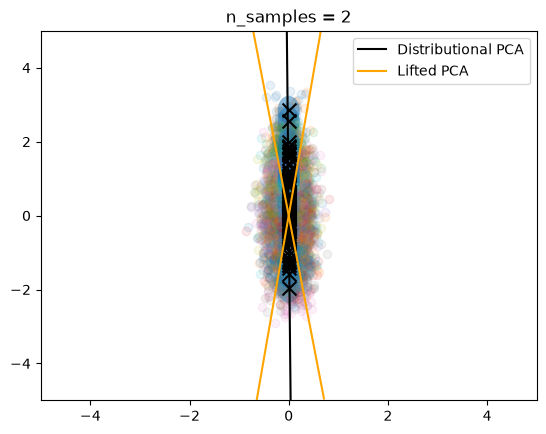

n=2 Lifted 0.030163431838154793 Distributional 0.05051364794373512


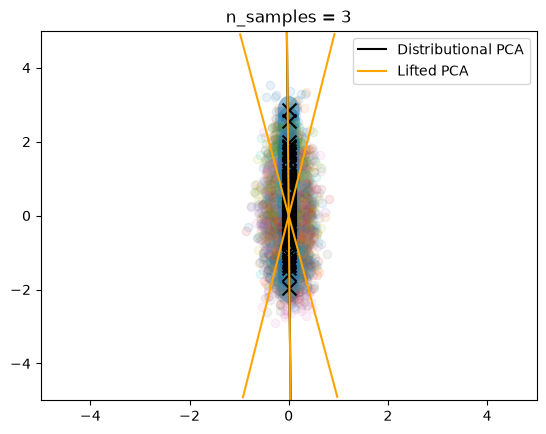

n=3 Lifted 0.024382332898676397 Distributional 0.05051364794373512


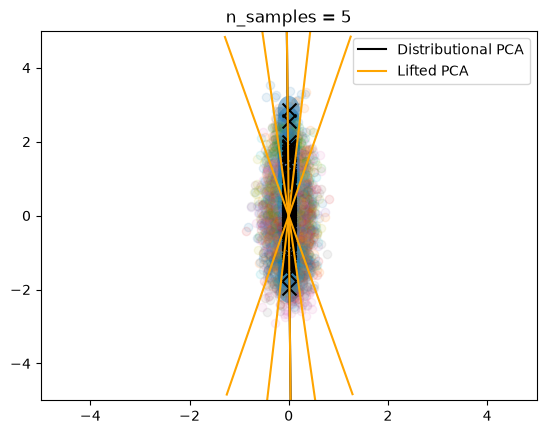

n=5 Lifted 0.02020111246500164 Distributional 0.05051364794373512


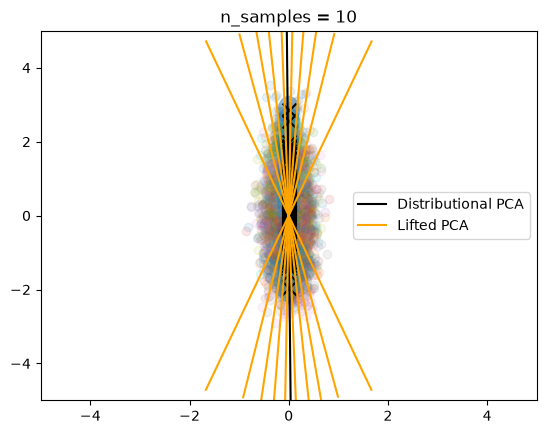

n=10 Lifted 0.017461701813153922 Distributional 0.05051364794373512


In [ ]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

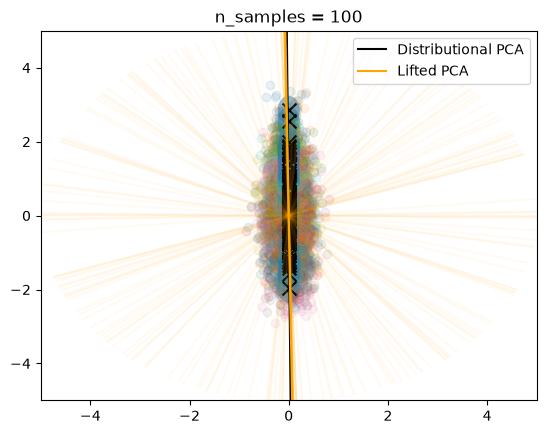

0.04524046216160059


In [ ]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", lr_bary=0.1)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [13]:
lifted_pca.weights_

tensor([1.5722e-04, 2.0725e-05, 2.3858e-06, 3.4138e-06, 2.0960e-04, 2.3809e-06,
        1.7851e-06, 4.4425e-06, 2.9209e-03, 3.9981e-06, 6.3746e-06, 1.8372e-06,
        4.2434e-04, 3.7916e-04, 1.7853e-06, 9.0896e-06, 3.3003e-06, 2.4240e-06,
        2.4178e-03, 7.3518e-05, 2.8084e-05, 5.5772e-03, 3.8810e-05, 7.1147e-06,
        1.0698e-04, 1.4212e-05, 1.8088e-03, 4.9728e-06, 1.1931e-04, 4.3703e-01,
        5.9463e-06, 2.3773e-06, 1.6794e-05, 2.1029e-06, 2.8111e-06, 1.2546e-05,
        7.3739e-04, 2.0548e-05, 2.1380e-06, 3.9256e-06, 4.3510e-06, 1.8052e-06,
        2.9098e-03, 1.8608e-04, 2.4867e-06, 7.4099e-06, 2.3345e-06, 1.7863e-06,
        1.7110e-02, 3.0813e-06, 4.0021e-02, 2.2447e-06, 2.9110e-06, 1.7853e-06,
        4.2132e-06, 1.1816e-01, 4.9831e-05, 1.8665e-06, 6.9425e-06, 3.4613e-06,
        1.7851e-06, 7.1314e-06, 5.9337e-06, 2.6107e-05, 1.8028e-06, 1.0146e-05,
        1.1717e-04, 2.0743e-06, 2.2303e-06, 4.2709e-06, 1.2198e-05, 6.7563e-06,
        2.1586e-06, 7.5048e-06, 3.5241e-

In [14]:
lifted_pca.weights_.max()

tensor(0.4370)

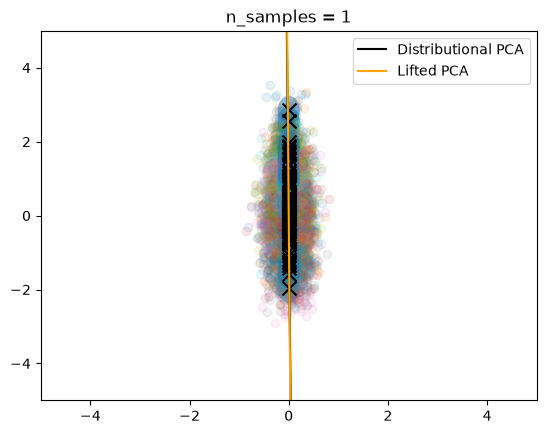

n=1 Lifted 0.05051559628918767 Distributional 0.05051364794373512
[1.]


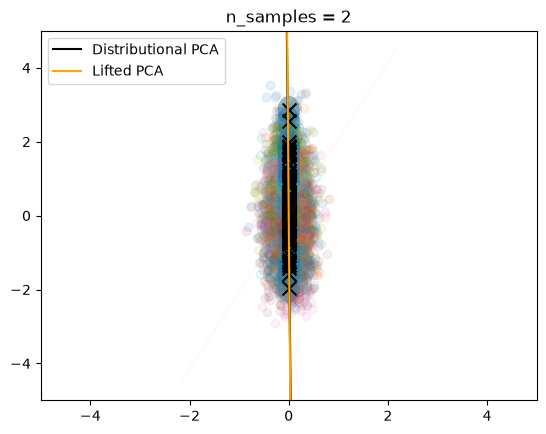

n=2 Lifted 0.050515593495219946 Distributional 0.05051364794373512
[1.0000000e+00 2.0326212e-08]


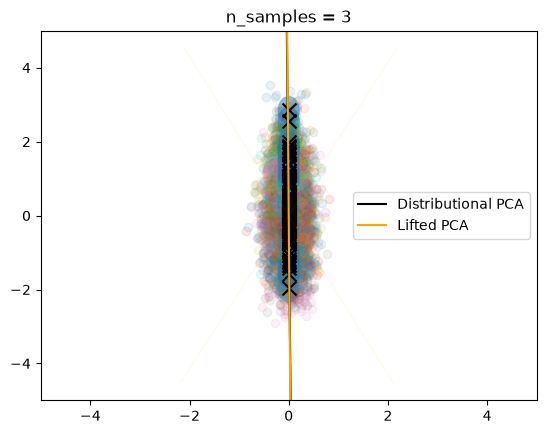

n=3 Lifted 0.05051559207960963 Distributional 0.05051364794373512
[1.0000000e+00 2.2195302e-08 1.2517674e-08]


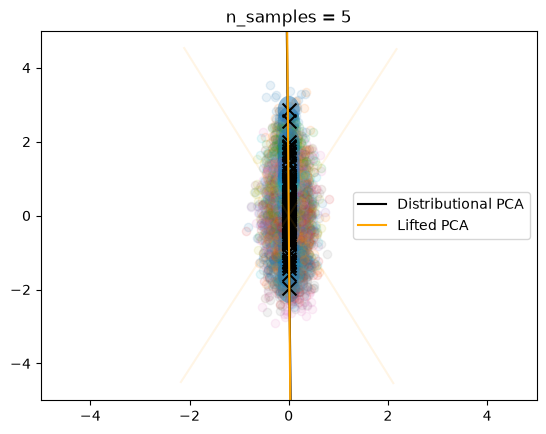

n=5 Lifted 0.05051559740677476 Distributional 0.05051364794373512
[5.5277227e-10 5.0197984e-09 1.0000000e+00 2.8376015e-10 7.7067472e-09]


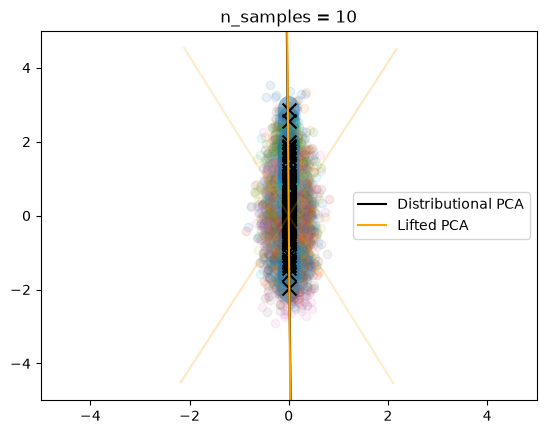

n=10 Lifted 0.05051559366285801 Distributional 0.05051364794373512
[2.2701897e-13 1.1775601e-14 1.0000000e+00 1.5281873e-12 2.1451072e-14
 3.3571279e-13 5.8022455e-14 1.1802934e-12 9.4684270e-14 3.6530516e-08]


In [ ]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())

## 2 Clear PC

In [16]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

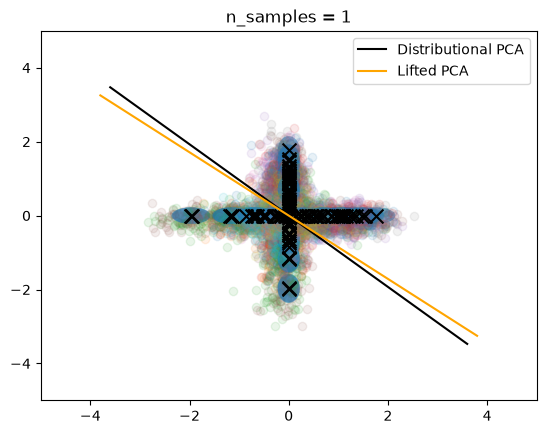

n=1 Lifted 0.4863806875050068 Distributional 0.48630269601941106


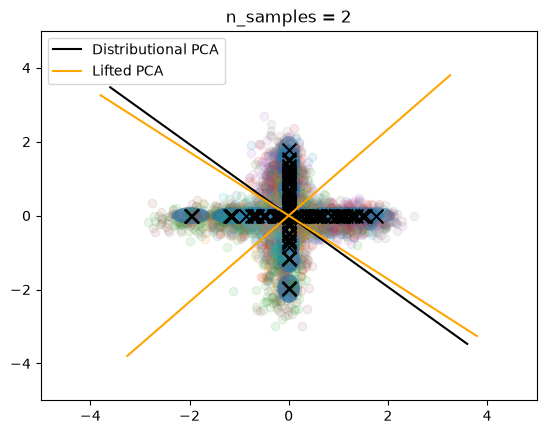

n=2 Lifted 0.3518517427518964 Distributional 0.48630269601941106


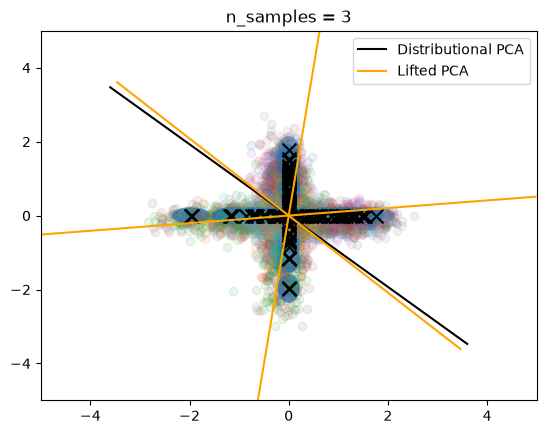

n=3 Lifted 0.24786935123614967 Distributional 0.48630269601941106


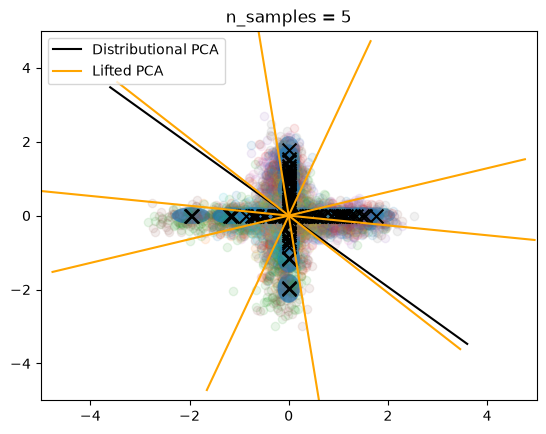

n=5 Lifted 0.2189704083278775 Distributional 0.48630269601941106


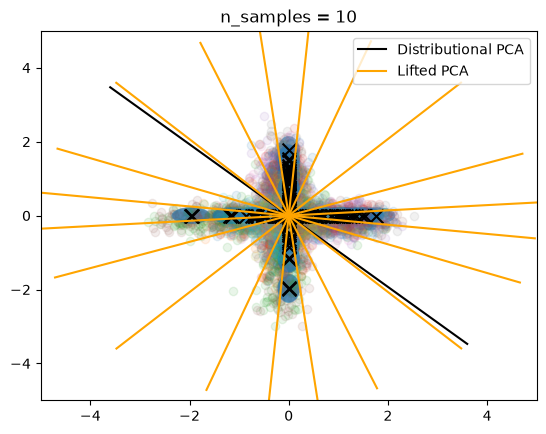

n=10 Lifted 0.20589788472512738 Distributional 0.48630269601941106


In [ ]:
# Vary number of Dirac
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

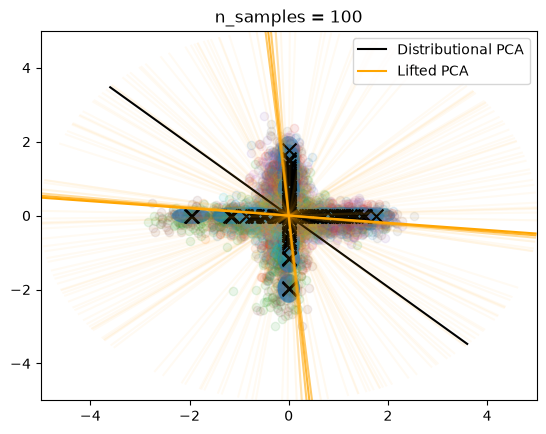

0.2616030519641936


In [ ]:
# Fix the support and optim over weights only
lifted_pca = LiftedPCA(n_components=1, n_samples=100)
lifted_pca.fit(samples, solver="fixed_support", seed=42, n_iter_bary=500, stop_threshold_fixed_support=1e-20)
eigenvectors_lifted = lifted_pca.components_

# Distributional PCA
pca_distributional = UAPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas,
     title="n_samples = "+str(100), weights=lifted_pca.weights_.numpy())

print(lifted_pca.cost_barycenter(samples))

In [19]:
lifted_pca.weights_

tensor([6.6589e-06, 6.3133e-05, 3.6483e-05, 8.6773e-04, 5.3959e-05, 2.9877e-05,
        6.6755e-06, 2.1308e-05, 2.1901e-01, 2.2154e-05, 2.5390e-05, 1.1439e-05,
        6.1915e-06, 1.2185e-05, 2.9339e-03, 1.9667e-04, 7.8519e-06, 9.3355e-03,
        2.3793e-05, 7.8022e-05, 3.1648e-05, 7.2683e-06, 3.1369e-05, 1.5186e-05,
        6.9708e-06, 1.0501e-04, 7.0624e-05, 6.2492e-06, 3.6013e-03, 1.2557e-01,
        2.8370e-02, 2.1838e-05, 8.3764e-06, 4.0554e-05, 3.9123e-05, 2.2242e-05,
        1.3385e-04, 1.2860e-04, 2.1488e-05, 1.9907e-05, 6.9566e-03, 1.2837e-05,
        6.1888e-06, 4.8662e-04, 3.1006e-05, 3.8290e-05, 1.1050e-05, 1.7733e-05,
        1.8885e-03, 5.8612e-04, 6.2404e-06, 8.1396e-05, 3.6867e-04, 1.2635e-05,
        5.4270e-05, 1.6176e-03, 3.0215e-04, 2.3893e-05, 1.2994e-04, 2.4207e-05,
        2.7571e-02, 7.7949e-05, 2.3699e-05, 8.7413e-06, 9.7693e-06, 6.5884e-06,
        1.6818e-01, 6.2919e-06, 9.4862e-04, 4.9129e-05, 9.8638e-05, 2.1672e-05,
        2.1328e-05, 6.2622e-06, 2.4340e-

In [20]:
lifted_pca.weights_.max()

tensor(0.2190)

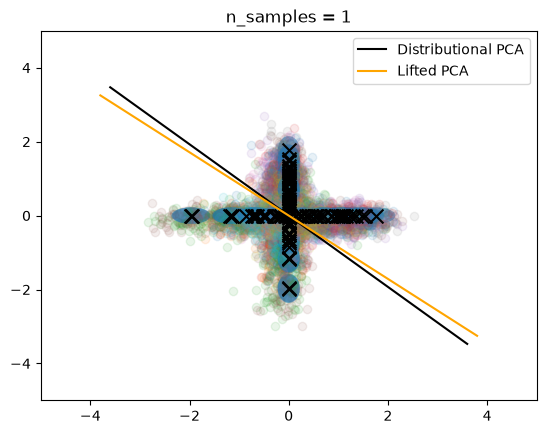

n=1 Lifted 0.4863806875050068 Distributional 0.48630269601941106
[1.]


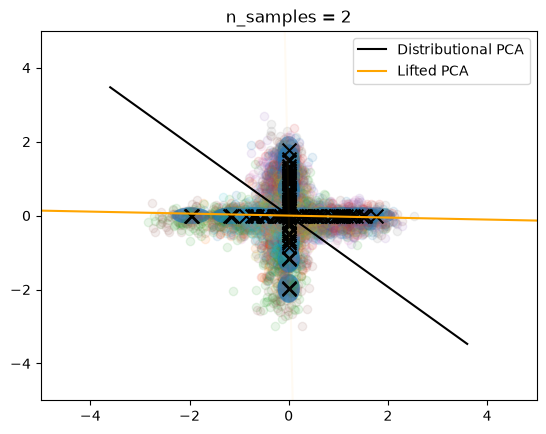

n=2 Lifted 0.2650432242825627 Distributional 0.48630269601941106
[0.49598724 0.50401276]


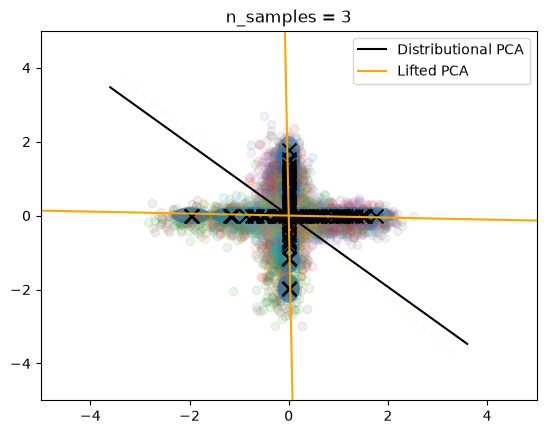

n=3 Lifted 0.265020668245852 Distributional 0.48630269601941106
[4.9582016e-01 8.4840191e-05 5.0409502e-01]


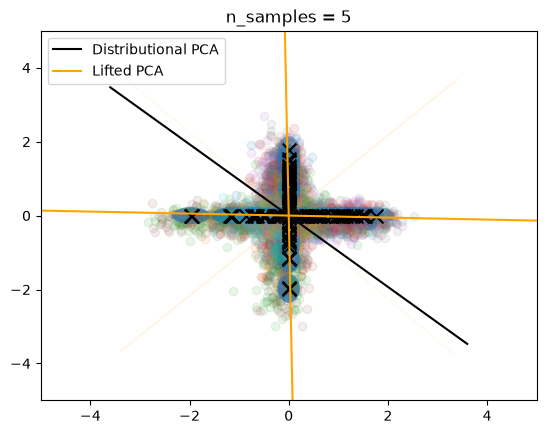

n=5 Lifted 0.26503568233922126 Distributional 0.48630269601941106
[3.3524250e-06 4.9584758e-01 5.0411773e-01 3.0458534e-05 9.5299333e-07]


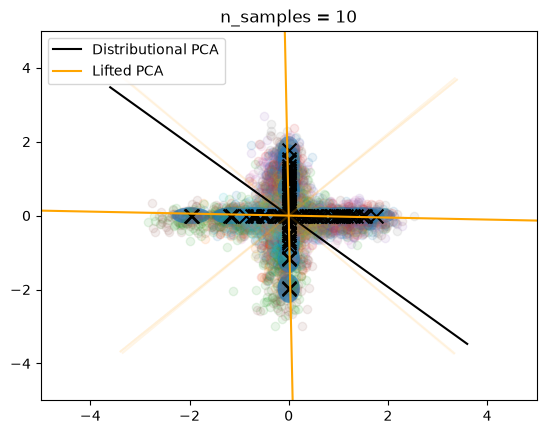

n=10 Lifted 0.26503152918070555 Distributional 0.48630269601941106
[5.0406659e-01 4.9588940e-01 3.9642814e-06 3.1886900e-06 8.4567091e-08
 1.6212660e-05 1.6629056e-05 2.4303574e-07 2.2948730e-07 3.4703967e-06]


In [ ]:
# Vary number of Dirac, optim over weights and support
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples, solver="free")
    eigenvectors_lifted = lifted_pca.components_
    
    # Distributional PCA
    pca_distributional = UAPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(eigenvectors_lifted, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples),
        weights=lifted_pca.weights_.numpy())

    print(
        "n="+str(n_samples), "Lifted", lifted_pca.cost_barycenter(samples),
        "Distributional", pca_distributional.cost_barycenter(samples)
    )

    print(lifted_pca.weights_.numpy())